# 중국어 JSON의 SpeakerID 분포

AI Hub 외국인 한국어 발화 데이터의 중국어 라벨링 ZIP(Training/Validation)을 직접 읽어 `SpeakerID`별 JSON 개수를 집계한다.

- ZIP을 풀지 않고 내부 JSON을 순차 처리
- 전체 및 split별 화자 분포 확인
- Training/Validation 화자 중복 확인
- 결과를 CSV로 저장

In [7]:
from collections import Counter
from pathlib import Path
import json
import zipfile

import pandas as pd

try:
    import matplotlib.pyplot as plt
except ImportError:
    plt = None
    print('matplotlib가 없어 그래프 셀은 건너뜁니다. 필요하면: pip install matplotlib')

BASE_DIR = Path(
    '$SPEECH_AI_DATA/aihub/foreign_korean_speech/'
    '131.인공지능_학습을_위한_외국인_한국어_발화_음성_데이터/'
    '01.데이터_new_20220719'
)
OUTPUT_DIR = Path('$NATIONALITY_OUTPUTS/chinese_speakerid_distribution_output')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

zip_paths = {
    'Training': BASE_DIR / '1.Training/라벨링데이터/4._중국어.zip',
    'Validation': BASE_DIR / '2.Validation/라벨링데이터/4._중국어.zip',
}

for split, path in zip_paths.items():
    print(f'{split:10s}: {path} | exists={path.exists()} | size={path.stat().st_size / 1024**2:,.1f} MiB')

Training  : $SPEECH_AI_DATA/aihub/foreign_korean_speech/131.인공지능_학습을_위한_외국인_한국어_발화_음성_데이터/01.데이터_new_20220719/1.Training/라벨링데이터/4._중국어.zip | exists=True | size=385.5 MiB
Validation: $SPEECH_AI_DATA/aihub/foreign_korean_speech/131.인공지능_학습을_위한_외국인_한국어_발화_음성_데이터/01.데이터_new_20220719/2.Validation/라벨링데이터/4._중국어.zip | exists=True | size=48.2 MiB


## 집계

`SpeakerID`를 우선 사용하고, 값이 없을 때 `file_info.speakerID`를 사용한다. 두 필드가 동시에 존재하면서 서로 다른 경우도 별도로 센다.

In [8]:
def decode_json(raw):
    last_error = None
    for encoding in ('utf-8-sig', 'utf-8', 'cp949'):
        try:
            return json.loads(raw.decode(encoding))
        except (UnicodeDecodeError, json.JSONDecodeError) as error:
            last_error = error
    raise last_error


def extract_speaker_id(data):
    top_level = data.get('SpeakerID') or data.get('speakerID')
    nested = data.get('file_info', {}).get('speakerID')
    return top_level or nested, bool(top_level and nested and str(top_level) != str(nested))


split_counts = {}
country_json_counts = Counter()
country_speakers = {}
mother_tongue_counts = Counter()
language_class_counts = Counter()
sample_json = None
sample_json_location = None
quality_rows = []

for split, zip_path in zip_paths.items():
    counts = Counter()
    total_json = missing = mismatch = decode_errors = 0

    with zipfile.ZipFile(zip_path) as archive:
        json_names = [name for name in archive.namelist() if name.lower().endswith('.json')]
        for index, name in enumerate(json_names, start=1):
            total_json += 1
            try:
                data = decode_json(archive.read(name))
                if sample_json is None:
                    sample_json = data
                    sample_json_location = (split, name)
                speaker_id, is_mismatch = extract_speaker_id(data)
            except Exception:
                decode_errors += 1
                continue

            mismatch += is_mismatch
            if speaker_id is None or str(speaker_id).strip() == '':
                missing += 1
            else:
                speaker_id = str(speaker_id).strip()
                counts[speaker_id] += 1

                country = str(data.get('residence_info', {}).get('country') or '<MISSING>').strip()
                mother_tongue = str(data.get('skill_info', {}).get('motherTongue') or '<MISSING>').strip()
                language_class = str(data.get('skill_info', {}).get('languageClass') or '<MISSING>').strip()
                country_json_counts[country] += 1
                country_speakers.setdefault(country, set()).add(speaker_id)
                mother_tongue_counts[mother_tongue] += 1
                language_class_counts[language_class] += 1

            if index % 50000 == 0:
                print(f'{split}: {index:,}/{len(json_names):,}')

    split_counts[split] = counts
    quality_rows.append({
        'split': split,
        'json_count': total_json,
        'unique_speakers': len(counts),
        'missing_speaker_id': missing,
        'speaker_id_mismatch': mismatch,
        'decode_errors': decode_errors,
    })
    print(f'{split} 완료: JSON {total_json:,}개, 화자 {len(counts):,}명')

quality_df = pd.DataFrame(quality_rows)
quality_df

Training: 50,000/233,756
Training: 100,000/233,756
Training: 150,000/233,756
Training: 200,000/233,756
Training 완료: JSON 233,756개, 화자 392명
Validation 완료: JSON 29,208개, 화자 387명


,split,json_count,unique_speakers,missing_speaker_id,speaker_id_mismatch,decode_errors
0,Training,233756,392,0,0,0
1,Validation,29208,387,0,0,0


## JSON 원문 전체 출력 및 국가 코드 확인

`residence_info.country`를 국적/출신 국가 코드로 보고 집계한다. `motherTongue`와 `languageClass`도 함께 확인한다.

In [9]:
print('JSON 위치:', sample_json_location)
print(json.dumps(sample_json, ensure_ascii=False, indent=2))

JSON 위치: ('Training', '1. ╟╤▒╣└╧╣▌/CN10QC226_CN0001_20210827.json')
{
  "fileName": "CN10QC226_CN0001_20210827.wav",
  "file_info": {
    "speakerID": "CN0001",
    "sentenceID": "CN10QC226",
    "recordUnit": "ios",
    "recordQuality": "16bit 16kHz MONO",
    "recordDate": "2021-08-27 19:21:29",
    "recordTime": "11.54"
  },
  "transcription": {
    "Reading": "",
    "ReadingLabelText": "",
    "Question": "당신은 어느 나라에서 왔나요? 한국에 온 이유는 무엇인가요?",
    "AnswerLabelText": "저는 중국에서 왔어요 한국에 온 이유는 유학하고 나중에 여기서도 일하고 싶어요",
    "SentenceSpeechLV": "중"
  },
  "SpeakerID": "CN0001",
  "basic_info": {
    "gender": "F",
    "birthYear": "2000",
    "eduBackground": "고졸"
  },
  "residence_info": {
    "country": "CN",
    "residencePeriod": "1년 이상 3년 미만",
    "residenceCity": "KR-11"
  },
  "skill_info": {
    "languageClass": "중국어",
    "motherTongue": "중국어",
    "selfAssessment": "상",
    "topikGrade": "5",
    "LearningPeriod": "48",
    "learningSource": "학원"
  }
}


In [10]:
country_df = pd.DataFrame([
    {
        'country': country,
        'json_count': json_count,
        'speaker_count': len(country_speakers[country]),
        'is_CN': country == 'CN',
    }
    for country, json_count in country_json_counts.most_common()
])

display(country_df)
print('\nmotherTongue:', dict(mother_tongue_counts))
print('languageClass:', dict(language_class_counts))
print('\nCN 이외 국가 코드의 화자 수:', int(country_df.loc[~country_df.is_CN, 'speaker_count'].sum()))

,country,json_count,speaker_count,is_CN
0,CN,217483,320,True
1,TW,14968,25,False
2,KR,14893,26,False
3,MY,10274,13,False
4,SG,1706,3,False
5,HK,1355,3,False
6,US,1344,1,False
7,FR,941,1,False



motherTongue: {'중국어': 262964}
languageClass: {'중국어': 262964}

CN 이외 국가 코드의 화자 수: 72


In [11]:
all_speakers = sorted(set().union(*(counts.keys() for counts in split_counts.values())))
distribution_df = pd.DataFrame({'SpeakerID': all_speakers})

for split, counts in split_counts.items():
    distribution_df[split] = distribution_df['SpeakerID'].map(counts).fillna(0).astype(int)

distribution_df['Total'] = distribution_df[list(split_counts)].sum(axis=1)
distribution_df = distribution_df.sort_values(
    ['Total', 'SpeakerID'], ascending=[False, True]
).reset_index(drop=True)

display(distribution_df.head(30))
print(f'전체 JSON: {distribution_df.Total.sum():,}개')
print(f'전체 고유 SpeakerID: {len(distribution_df):,}명')

,SpeakerID,Training,Validation,Total
0,CN0116,1450,185,1635
1,CN0197,1441,179,1620
2,CN0240,1457,161,1618
3,CN0279,1421,179,1600
4,CN0165,1426,170,1596
5,CN0274,1376,195,1571
6,CN0219,1409,156,1565
7,CN0192,1357,178,1535
8,CN0301,1325,163,1488
9,CN0186,1308,164,1472


전체 JSON: 262,964개
전체 고유 SpeakerID: 392명


In [12]:
summary_rows = []
for column in [*split_counts.keys(), 'Total']:
    values = distribution_df.loc[distribution_df[column] > 0, column]
    summary_rows.append({
        'split': column,
        'speakers': len(values),
        'json_count': int(values.sum()),
        'min_per_speaker': int(values.min()),
        'median_per_speaker': float(values.median()),
        'mean_per_speaker': round(float(values.mean()), 2),
        'max_per_speaker': int(values.max()),
    })

summary_df = pd.DataFrame(summary_rows)
display(summary_df)

train_speakers = set(split_counts['Training'])
valid_speakers = set(split_counts['Validation'])
overlap = train_speakers & valid_speakers

print(f'Training 화자: {len(train_speakers):,}명')
print(f'Validation 화자: {len(valid_speakers):,}명')
print(f'Train/Validation 중복 화자: {len(overlap):,}명')
print(f'Training 전용: {len(train_speakers - valid_speakers):,}명')
print(f'Validation 전용: {len(valid_speakers - train_speakers):,}명')

,split,speakers,json_count,min_per_speaker,median_per_speaker,mean_per_speaker,max_per_speaker
0,Training,392,233756,1,485.5,596.32,1457
1,Validation,387,29208,1,63.0,75.47,195
2,Total,392,262964,1,544.5,670.83,1635


Training 화자: 392명
Validation 화자: 387명
Train/Validation 중복 화자: 387명
Training 전용: 5명
Validation 전용: 0명


/tmp/ipykernel_1124028/3418967895.py:22: UserWarning: Glyph 48324 (\N{HANGUL SYLLABLE BYEOL}) missing from current font.
  plt.tight_layout()
/tmp/ipykernel_1124028/3418967895.py:22: UserWarning: Glyph 44060 (\N{HANGUL SYLLABLE GAE}) missing from current font.
  plt.tight_layout()
/tmp/ipykernel_1124028/3418967895.py:22: UserWarning: Glyph 49688 (\N{HANGUL SYLLABLE SU}) missing from current font.
  plt.tight_layout()
/tmp/ipykernel_1124028/3418967895.py:22: UserWarning: Glyph 49345 (\N{HANGUL SYLLABLE SANG}) missing from current font.
  plt.tight_layout()
/tmp/ipykernel_1124028/3418967895.py:22: UserWarning: Glyph 50948 (\N{HANGUL SYLLABLE WI}) missing from current font.
  plt.tight_layout()
/tmp/ipykernel_1124028/3418967895.py:22: UserWarning: Glyph 47749 (\N{HANGUL SYLLABLE MYEONG}) missing from current font.
  plt.tight_layout()
/tmp/ipykernel_1124028/3418967895.py:22: UserWarning: Glyph 54868 (\N{HANGUL SYLLABLE HWA}) missing from current font.
  plt.tight_layout()
/tmp/ipykernel_1

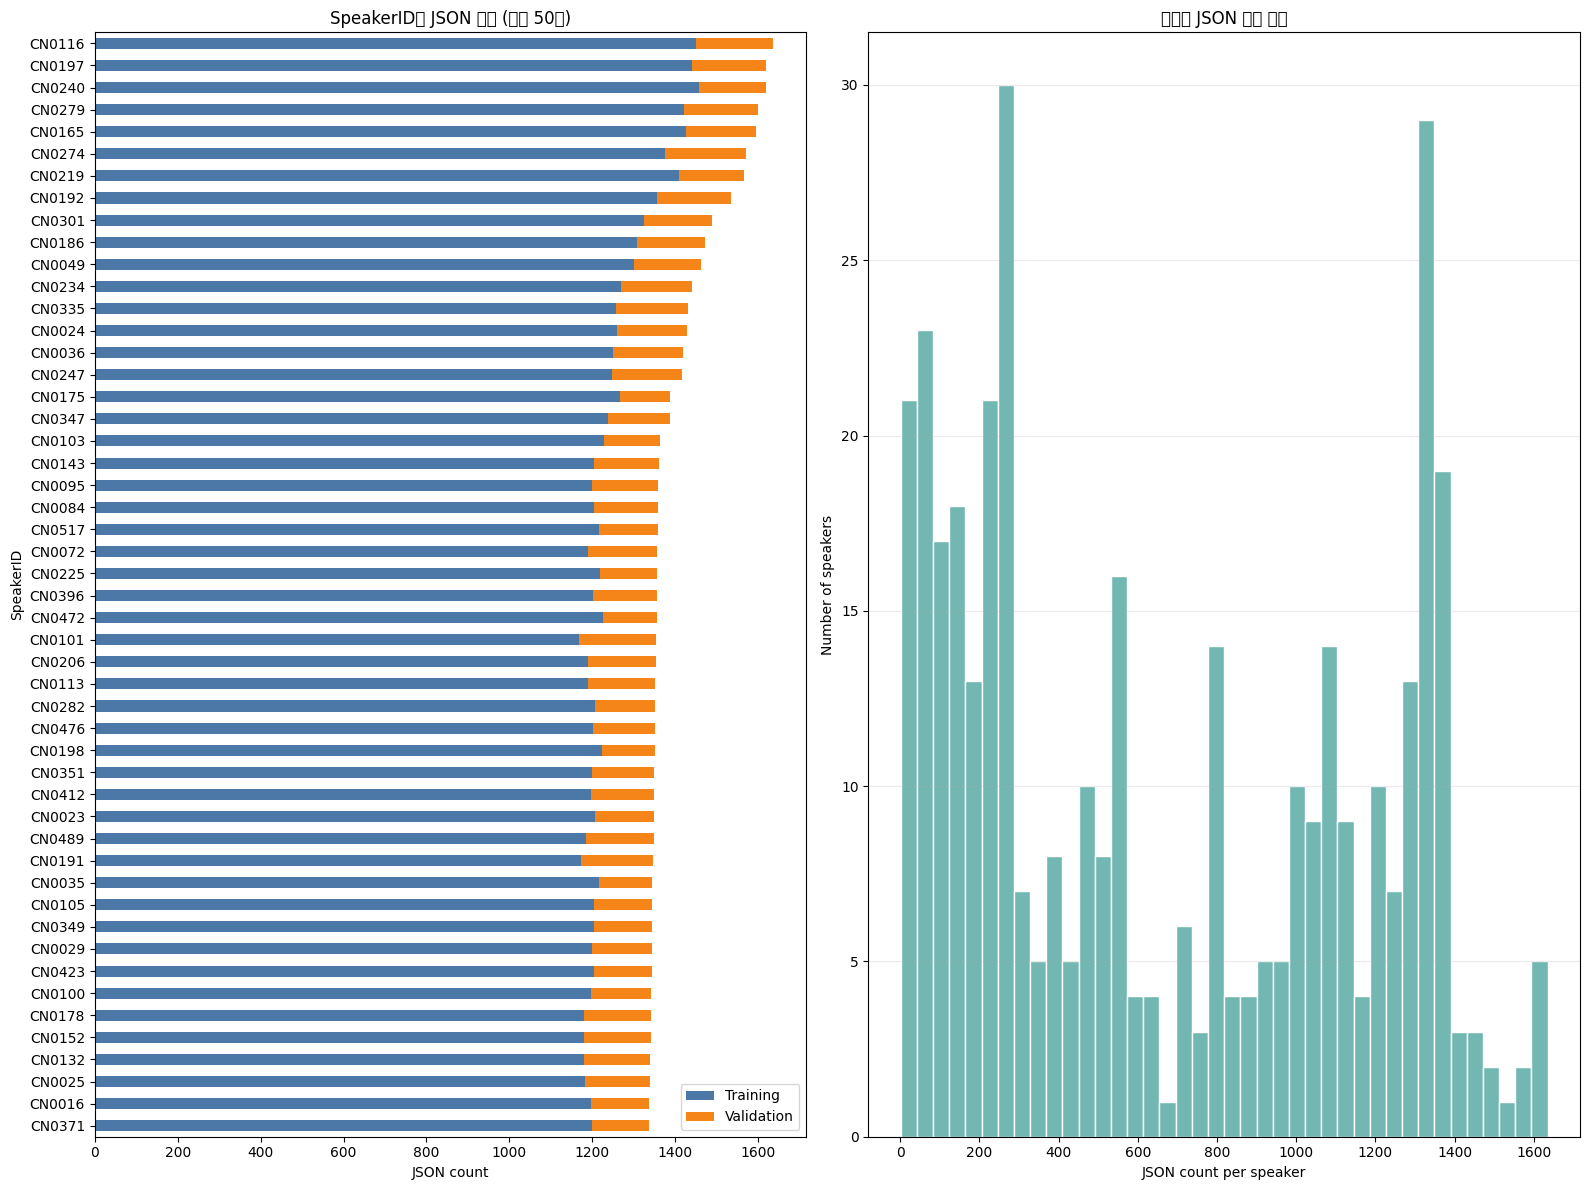

In [13]:
if plt is None:
    print('matplotlib 미설치: 그래프를 건너뜁니다.')
else:
    top_n = min(50, len(distribution_df))
    top_df = distribution_df.head(top_n).sort_values('Total')
    fig, axes = plt.subplots(1, 2, figsize=(16, max(6, top_n * 0.24)))

    top_df.plot.barh(
        x='SpeakerID', y=['Training', 'Validation'], stacked=True,
        ax=axes[0], color=['#4C78A8', '#F58518']
    )
    axes[0].set_title(f'SpeakerID별 JSON 개수 (상위 {top_n}명)')
    axes[0].set_xlabel('JSON count')
    axes[0].set_ylabel('SpeakerID')

    axes[1].hist(distribution_df['Total'], bins=40, color='#72B7B2', edgecolor='white')
    axes[1].set_title('화자별 JSON 개수 분포')
    axes[1].set_xlabel('JSON count per speaker')
    axes[1].set_ylabel('Number of speakers')
    axes[1].grid(axis='y', alpha=0.25)

    plt.tight_layout()
    plt.show()

In [14]:
distribution_path = OUTPUT_DIR / 'chinese_speakerid_distribution.csv'
summary_path = OUTPUT_DIR / 'chinese_speakerid_summary.csv'
quality_path = OUTPUT_DIR / 'chinese_speakerid_data_quality.csv'

distribution_df.to_csv(distribution_path, index=False, encoding='utf-8-sig')
summary_df.to_csv(summary_path, index=False, encoding='utf-8-sig')
quality_df.to_csv(quality_path, index=False, encoding='utf-8-sig')

print(distribution_path)
print(summary_path)
print(quality_path)

$NATIONALITY_OUTPUTS/chinese_speakerid_distribution_output/chinese_speakerid_distribution.csv
$NATIONALITY_OUTPUTS/chinese_speakerid_distribution_output/chinese_speakerid_summary.csv
$NATIONALITY_OUTPUTS/chinese_speakerid_distribution_output/chinese_speakerid_data_quality.csv
